# Does the interaction energy obey its theoretical scalings?

The interaction term is the one piece of the Gross-Pitaevskii equation that has no counterpart in
the linear Schrödinger problem, and it is the easiest one to get wrong by a constant: a factor of
two between the equation and the energy functional, a missing volume element, an atom number that
enters twice. None of those mistakes shows up as an instability — the solver still converges, to
a wrong answer.

This notebook checks the interaction energy

$$
E_\mathrm{int} = \frac{g}{2}\int |\psi|^4 \, \mathrm{d}^2r
$$

of the `GroundStateSSFM` ground state against four theoretical results, chosen so that between
them they pin down everything that could be wrong:

| | Check | What it would catch |
|---|---|---|
| 1 | $E_\mathrm{int}(g, N) = N \, E_\mathrm{int}(gN, 1)$ | `population` and `g` not entering consistently |
| 2 | $E_\mathrm{int}/g \to N^2/(4\pi a_\mathrm{ho}^2)$ as $g\to 0$ | **a wrong constant** — factor of 2, missing $\mathrm{d}S$ |
| 3 | $E_\mathrm{int} \to \mu N/3$, $\mu = \omega\sqrt{gN/\pi}$ | a wrong *exponent* in the strongly interacting limit |
| 4 | $E_\mathrm{kin} + E_\mathrm{int} = E_\mathrm{trap}$ | anything else — it is exact at every coupling |

Checks 2 and 3 are asymptotic and approach their targets from opposite ends of the coupling range.
Check 4 holds everywhere and turns out to be the sharpest numerical diagnostic in the package.

## A note on what `solve` returns

`GroundStateSSFM.solve` returns $\langle\psi|H_\mathrm{GP}|\psi\rangle$. Because $H_\mathrm{GP}$
carries the *full* $g|\psi|^2$, that number is the chemical potential $\mu N$, **not** the energy
functional:

$$
\mu N = E_\mathrm{kin} + \int V|\psi|^2 + g\!\int|\psi|^4,
\qquad
E = E_\mathrm{kin} + \int V|\psi|^2 + \frac{g}{2}\!\int|\psi|^4 .
$$

The two differ by exactly $E_\mathrm{int}$, so the interaction energy cannot be read off the
returned value alone. `energy_components` reports the pieces separately, and that is what the
rest of this notebook uses.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from bloch_schrodinger.potential import Potential, create_parameter

from BECs.groundstate import GroundStateSSFM

%matplotlib inline

# --- plotting style: recessive axes, ink for text, hues only for the data itself ---
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, RULE = "#0b0b0b", "#52514e", "#c9c8c4"
plt.rcParams.update({
    "figure.figsize": (7.2, 4.2), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e8e8e6", "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "lines.linewidth": 2, "lines.markersize": 7,
    "legend.frameon": False, "legend.fontsize": 9, "legend.labelcolor": INK_2,
    "font.size": 10,
})

## Conventions

Everything below is 2D with $\hbar = m = 1$ and an isotropic trap $V = \tfrac12\omega^2 r^2$ with
$\omega = 1$, so the oscillator length is $a_\mathrm{ho} = 1$. The wavefunction is normalised to the
population, $\int|\psi|^2\,\mathrm{d}S = N$, which is what `SpectralSolver.normalize` imposes.

Writing $\psi = \sqrt{N}\,\phi$ with $\int|\phi|^2 = 1$ turns the nonlinear term into
$g|\psi|^2 = gN|\phi|^2$: **the coupling and the atom number only ever appear as the product
$gN$.** That is the basis of check 1 and the reason every later check can be run at $N = 1$
without loss of generality.

The trap is written out explicitly rather than through `BECs.ufuncs.harmonic2D`, because that
helper's `omega_x` argument is really $\omega^2$ — it forms `omega_x / 2 * x**2` — and the whole
point here is getting the Thomas-Fermi prefactor right.

In [2]:
L, N_GRID = 30.0, 256          # box side and resolution
OMEGA, A_HO = 1.0, 1.0         # trap frequency and oscillator length, hbar = m = 1

def make_trap(L=L, n=N_GRID, omega=OMEGA):
    "An isotropic 2D harmonic trap V = omega^2 r^2 / 2 on a square box of side L."
    pot = Potential(unitvecs=[[L, 0], [0, L]], resolution=(n, n), v0=0)
    pot.set(0.5 * omega**2 * (pot.x**2 + pot.y**2))
    return pot

# tol_stop is the accuracy knob: the solver stops once the Gross-Pitaevskii residual of the state
# falls below it, lowering its time step as far as needed to get there. tol_adapt only steers the
# step-size controller on the way. The last section measures the dependence.
TOL_ADAPT, TOL_STOP = 1e-8, 1e-7

def ground_state_components(pot, g, population=1.0, **kw):
    "Solve for the ground state and return its energy budget as an xr.Dataset."
    solver = GroundStateSSFM(pot, g)
    kw = {"tol_adapt": TOL_ADAPT, "tol_stop": TOL_STOP, "verbose": False, "device": "cpu", **kw}
    _, psi = solver.solve(population=population, **kw)
    return solver.energy_components(psi)

trap = make_trap()
print(f"box {L} x {L}, grid {N_GRID}^2, dS = {trap.get_dS():.3e}")

box 30.0 x 30.0, grid 256^2, dS = 1.373e-02


## 1. The $gN$ invariance

This one needs no physics input at all. Since $g$ and $N$ enter only through $gN$, and since
$E_\mathrm{int} = \tfrac{g}{2}N^2\!\int|\phi|^4$ is quadratic in the amplitude,

$$
E_\mathrm{int}(g, N) = N \cdot E_\mathrm{int}(gN, 1) .
$$

It is a statement about the *wiring* rather than about the solution: if `population=` and `g` were
applied inconsistently — say the normalisation used $\sum|\psi|^2$ where it meant
$\mathrm{d}S\sum|\psi|^2$ — the two sides would drift apart. It costs two solves per row.

In [3]:
rows = []
for g, n_atoms in [(2.0, 5.0), (0.5, 20.0), (100.0, 3.0), (0.01, 50.0)]:
    direct = ground_state_components(trap, g, population=n_atoms)
    scaled = ground_state_components(trap, g * n_atoms, population=1.0)
    lhs, rhs = float(direct.interaction), n_atoms * float(scaled.interaction)
    rows.append((g, n_atoms, lhs, rhs, abs(lhs - rhs) / abs(lhs)))

print(f"{'g':>8} {'N':>6} {'E_int(g,N)':>13} {'N.E_int(gN,1)':>15} {'rel. diff':>11}")
for g, n_atoms, lhs, rhs, rel in rows:
    print(f"{g:8g} {n_atoms:6g} {lhs:13.8f} {rhs:15.8f} {rel:11.2e}")

worst_invariance = max(r[-1] for r in rows)
print(f"\nworst relative difference: {worst_invariance:.2e}")

       g      N    E_int(g,N)   N.E_int(gN,1)   rel. diff
       2      5    2.35716418      2.35716419    3.89e-10
     0.5     20    9.42865674      9.42865674    7.80e-10
     100      3    9.63309316      9.63309316    3.92e-10
    0.01     50    1.90404914      1.90404914    8.24e-10

worst relative difference: 8.24e-10


## 2. The weak-coupling limit — the absolute prefactor

As $g \to 0$ the density relaxes to the non-interacting Gaussian
$\phi_0 = (\sqrt{\pi}\,a_\mathrm{ho})^{-1}e^{-r^2/2a_\mathrm{ho}^2}$, for which
$\int|\phi_0|^4\,\mathrm{d}^2r = 1/(2\pi a_\mathrm{ho}^2)$. Evaluating the interaction energy on
that unperturbed profile gives a limit with **no free constant**:

$$
\frac{E_\mathrm{int}}{g} \;\xrightarrow[g\to 0]{}\; \frac{N^2}{4\pi a_\mathrm{ho}^2}
\;=\; \frac{1}{4\pi} \;=\; 0.0795775\ldots \quad (N = 1,\ a_\mathrm{ho} = 1).
$$

This is the check that catches a wrong constant. A missing $\tfrac12$ would land on $0.159$, a
missing volume element would be off by orders of magnitude. Nothing about it is asymptotic except
the shape of the density, so the agreement should be excellent at small $g$ and then degrade
smoothly as the cloud starts to spread.

## 3. The Thomas-Fermi limit — the exponent

At large $gN$ the kinetic term is negligible and the density follows the inverted trap,
$n = (\mu - V)/g$ inside the cloud. Normalising in 2D gives $N = \pi\mu^2/(g\omega^2)$, hence

$$
\mu = \omega\sqrt{\frac{gN}{\pi}}, \qquad
E_\mathrm{int} = \frac{\mu N}{3}, \qquad
E_\mathrm{int} \propto (gN)^{1/2} .
$$

So this limit fixes the *exponent* — $E_\mathrm{int}$ must grow as the square root of the coupling,
not linearly as it does at weak coupling — and it also fixes the ratio $E_\mathrm{int}/(\mu N/3)$
to 1 and the Thomas-Fermi radius to $R_\mathrm{TF} = \sqrt{2\mu}/\omega$.

That radius carries a caveat that has to be respected or the check misreads: the cloud must still
fit in the box. Past $R_\mathrm{TF} \approx L/2$ the periodic grid wraps the cloud into itself and
every quantity above degrades — a box artefact, not a solver error. The sweep below reports
$R_\mathrm{TF}/(L/2)$ so that it stays visible.

In [4]:
g_sweep = np.logspace(-3, 4, 15)
sweep = ground_state_components(trap, create_parameter("g", g_sweep), population=1.0)

weak_ratio = (sweep.interaction / g_sweep) / (1.0 / (4 * np.pi * A_HO**2))   # -> 1 as g -> 0
mu_tf = OMEGA * np.sqrt(g_sweep / np.pi)
tf_ratio = sweep.interaction / (sweep.mu / 3)                                # -> 1 as g -> inf
r_tf_frac = np.sqrt(2 * sweep.mu) / OMEGA / (L / 2)

print(f"{'g':>9} {'E_int':>11} {'weak ratio':>11} {'TF ratio':>9} {'mu':>10} {'mu_TF':>10} {'R_TF/(L/2)':>11}")
for i, g in enumerate(g_sweep):
    print(f"{g:9.2e} {float(sweep.interaction[i]):11.6f} {float(weak_ratio[i]):11.6f} "
          f"{float(tf_ratio[i]):9.5f} {float(sweep.mu[i]):10.5f} {mu_tf[i]:10.5f} {float(r_tf_frac[i]):11.3f}")

        g       E_int  weak ratio  TF ratio         mu      mu_TF  R_TF/(L/2)
 1.00e-03    0.000080    0.999908   0.00024    1.00016    0.01784       0.094
 3.16e-03    0.000252    0.999710   0.00075    1.00050    0.03173       0.094
 1.00e-02    0.000795    0.999085   0.00238    1.00159    0.05642       0.094
 3.16e-02    0.002509    0.997116   0.00749    1.00502    0.10033       0.095
 1.00e-01    0.007886    0.990964   0.02329    1.01581    0.17841       0.095
 3.16e-01    0.024465    0.972218   0.06995    1.04928    0.31727       0.097
 1.00e+00    0.073145    0.919163   0.19092    1.14937    0.56419       0.101
 3.16e+00    0.200022    0.794855   0.42171    1.42295    1.00329       0.112
 1.00e+01    0.471433    0.592420   0.68530    2.06375    1.78412       0.135
 3.16e+01    0.963063    0.382705   0.86111    3.35519    3.17267       0.173
 1.00e+02    1.813810    0.227930   0.94473    5.75975    5.64190       0.226
 3.16e+02    3.298805    0.131089   0.97906   10.10805   10.0328

### Both limits in one view

The two ratios are normalised so that each tends to 1 in its own regime. Plotted together they
should approach that line from opposite ends of the coupling range, with the crossover somewhere
around $gN \sim 1$ where neither description is valid — which is exactly the expected shape of the
ideal-gas-to-Thomas-Fermi transition.

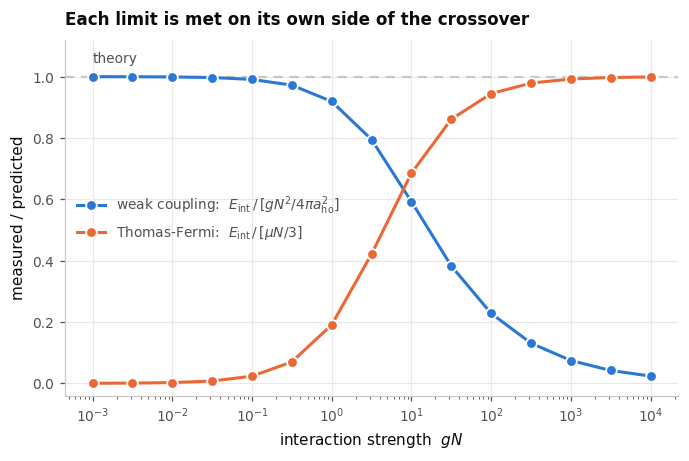

In [5]:
fig, ax = plt.subplots()
ax.axhline(1.0, color=RULE, lw=1.5, ls=(0, (4, 3)), zorder=1)
ax.text(g_sweep[0], 1.035, "theory", color=INK_2, fontsize=9, va="bottom")

for values, color, label in [
    (weak_ratio, BLUE, r"weak coupling:  $E_\mathrm{int}\,/\,[gN^2/4\pi a_\mathrm{ho}^2]$"),
    (tf_ratio, ORANGE, r"Thomas-Fermi:  $E_\mathrm{int}\,/\,[\mu N/3]$"),
]:
    ax.plot(g_sweep, values, color=color, marker="o", markeredgecolor="white",
            markeredgewidth=1.2, label=label, zorder=3)

ax.set_xscale("log")
ax.set_xlabel(r"interaction strength  $gN$")
ax.set_ylabel("measured / predicted")
ax.set_title("Each limit is met on its own side of the crossover")
ax.set_ylim(-0.04, 1.12)
ax.legend(loc="center left")
plt.show()

### The exponent, on log-log axes

The scaling itself is clearest as $E_\mathrm{int}$ against $g$ with both asymptotes drawn in. The
measured curve should leave the weak-coupling line of slope 1 and settle onto the Thomas-Fermi
line of slope $\tfrac12$.

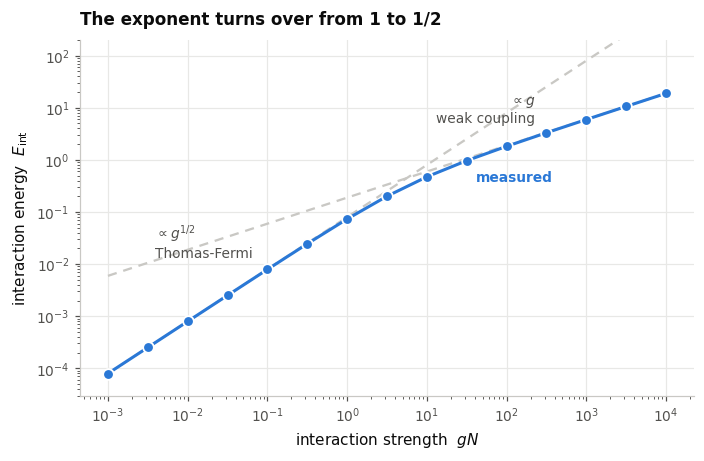

local slope d log E_int / d log g at g = 1e-03: 0.9998   (weak coupling: 1)
local slope d log E_int / d log g at g = 1e+04: 0.5010   (Thomas-Fermi: 0.5)


In [6]:
fig, ax = plt.subplots()

# both asymptotes run the full width, with the y-axis clamped to the data: each line then stays
# under the measured curve inside its own regime and visibly peels away outside it
ax.plot(g_sweep, g_sweep / (4 * np.pi * A_HO**2), color=RULE, lw=1.5, ls=(0, (4, 3)), zorder=1)
ax.plot(g_sweep, mu_tf / 3, color=RULE, lw=1.5, ls=(0, (4, 3)), zorder=1)
ax.plot(g_sweep, sweep.interaction, color=BLUE, marker="o", markeredgecolor="white",
        markeredgewidth=1.2, zorder=3)

ax.annotate(r"$\propto g$" "\n" "weak coupling", xy=(3e2, 3e2 / (4 * np.pi)),
            xytext=(-6, -4), textcoords="offset points", color=INK_2, fontsize=9,
            ha="right", va="top")
ax.annotate(r"$\propto g^{1/2}$" "\n" "Thomas-Fermi", xy=(3e-3, OMEGA * np.sqrt(3e-3 / np.pi) / 3),
            xytext=(6, 2), textcoords="offset points", color=INK_2, fontsize=9,
            ha="left", va="bottom")
ax.annotate("measured", xy=(g_sweep[9], float(sweep.interaction[9])),
            xytext=(6, -14), textcoords="offset points", color=BLUE, fontsize=9, weight="semibold")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_ylim(3e-5, 2e2)
ax.set_xlabel(r"interaction strength  $gN$")
ax.set_ylabel(r"interaction energy  $E_\mathrm{int}$")
ax.set_title("The exponent turns over from 1 to 1/2")
plt.show()

slopes = np.gradient(np.log(sweep.interaction.values), np.log(g_sweep))
print(f"local slope d log E_int / d log g at g = {g_sweep[0]:.0e}: {slopes[0]:.4f}   (weak coupling: 1)")
print(f"local slope d log E_int / d log g at g = {g_sweep[-1]:.0e}: {slopes[-1]:.4f}   (Thomas-Fermi: 0.5)")

## 4. The 2D virial identity

The three checks so far are asymptotic. This one is exact at every coupling, and it is specific to
two dimensions.

Consider the norm-preserving dilation $\phi_\lambda(r) = \lambda\,\phi(\lambda r)$, which keeps
$\int|\phi_\lambda|^2 = \int|\phi|^2$ in 2D. Under it the three terms scale as

$$
E_\mathrm{kin} \to \lambda^2 E_\mathrm{kin}, \qquad
E_\mathrm{int} \to \lambda^2 E_\mathrm{int}, \qquad
E_\mathrm{trap} \to \lambda^{-2} E_\mathrm{trap}.
$$

The interaction term scaling as $\lambda^2$ — the *same* power as the kinetic term — is the
peculiarity of 2D: $|\phi_\lambda|^4$ picks up $\lambda^4$ while $\mathrm{d}^2r$ gives back
$\lambda^{-2}$. Since the ground state minimises $E$, the derivative at $\lambda = 1$ must vanish:

$$
2E_\mathrm{kin} + 2E_\mathrm{int} - 2E_\mathrm{trap} = 0
\qquad\Longrightarrow\qquad
\boxed{\,E_\mathrm{kin} + E_\mathrm{int} = E_\mathrm{trap}\,}
$$

with no adjustable constant and no restriction on $g$. An interaction term that were off by a
factor would break it at every point of the sweep at once.

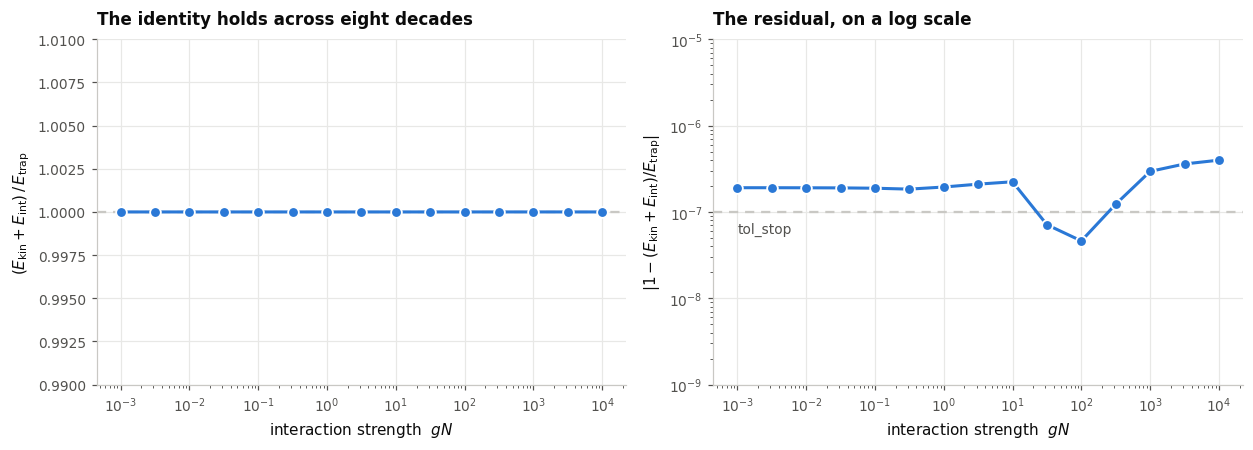

worst deviation from the virial identity: 3.98e-07  (at g = 1.00e+04)


In [7]:
virial = (sweep.kinetic + sweep.interaction) / sweep.potential
virial_dev = np.abs(1 - virial.values)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1, 1]})

ax.axhline(1.0, color=RULE, lw=1.5, ls=(0, (4, 3)), zorder=1)
ax.plot(g_sweep, virial.values, color=BLUE, marker="o", markeredgecolor="white",
        markeredgewidth=1.2, zorder=3)
ax.set_xscale("log")
ax.set_xlabel(r"interaction strength  $gN$")
ax.set_ylabel(r"$(E_\mathrm{kin} + E_\mathrm{int})\,/\,E_\mathrm{trap}$")
ax.set_title("The identity holds across eight decades")
ax.set_ylim(0.99, 1.01)

ax2.axhline(TOL_STOP, color=RULE, lw=1.5, ls=(0, (4, 3)), zorder=1)
ax2.text(g_sweep[0], TOL_STOP / 1.3, "tol_stop", color=INK_2, fontsize=9, va="top")
ax2.plot(g_sweep, virial_dev, color=BLUE, marker="o", markeredgecolor="white",
         markeredgewidth=1.2, zorder=3)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel(r"interaction strength  $gN$")
ax2.set_ylabel(r"$|1 - (E_\mathrm{kin}+E_\mathrm{int})/E_\mathrm{trap}|$")
ax2.set_title("The residual, on a log scale")
ax2.set_ylim(1e-9, 1e-5)
plt.tight_layout()
plt.show()

print(f"worst deviation from the virial identity: {virial_dev.max():.2e}  (at g = {g_sweep[virial_dev.argmax()]:.2e})")

## What sets the residual

The virial residual above is small but not at machine precision. What it measures is how far the
returned state is from a true stationary state of the Gross-Pitaevskii equation — and that is
exactly what `tol_stop` bounds.

The imaginary-time solver is a Strang split-step, and Strang splitting does not have the true
ground state as its fixed point: it has the ground state of a nearby effective problem, displaced
by $O(\mathrm{d}t^2)$. Iterating until successive states agree to the last bit therefore does not
reach the ground state, only that displaced fixed point. So `solve` stops on the residual of the
equation itself,

$$
\frac{\lVert P(H - \mu)\psi\rVert}{\lVert PH\psi\rVert} < \texttt{tol\_stop},
$$

with $P$ the anti-aliasing projector (`gp_residual`), and whenever the iterates have settled on a
fixed point that is still too far, it lowers a ceiling on $\mathrm{d}t$ and carries on:

- `tol_stop` decides *how close to the ground state* the returned state is,
- `tol_adapt` only steers the time step on the way there.

The cell below measures the dependence: the virial residual follows `tol_stop` down, decade for
decade.

There is a second lesson in the table. The chemical potential is *variational*: it is stationary
about the true ground state, so an error $\epsilon$ in the state perturbs it only at order
$\epsilon^2$, while the individual kinetic and trap energies are not stationary and move at order
$\epsilon$. So $\mu$ converges visibly faster than the state does, and comparing the two columns
below shows the practical consequence — **the returned energy cannot tell you the state is still
off; the virial residual can.**

In [8]:
conv = []
for tol_stop in [1e-5, 1e-6, 1e-7, 1e-8]:
    comps = ground_state_components(trap, 3.2, population=1.0, tol_stop=tol_stop)
    dev = abs(1 - float((comps.kinetic + comps.interaction) / comps.potential))
    conv.append((tol_stop, dev, float(comps.mu)))

mu_ref = conv[-1][2]
print(f"{'tol_stop':>10} {'virial residual':>16} {'mu':>12} {'mu - mu_ref':>13}")
for tol_stop, dev, mu in conv:
    print(f"{tol_stop:10.0e} {dev:16.2e} {mu:12.8f} {mu - mu_ref:+13.2e}")

ratio = conv[0][1] / conv[-1][1]
mu_rel = abs(conv[0][2] - mu_ref) / abs(mu_ref)
print(f"\nover a 1e3 reduction in tol_stop the virial residual falls {ratio:.0f}x, "
      f"from {conv[0][1]:.1e} to {conv[-1][1]:.1e}")
print(f"across the same range mu moves by {mu_rel:.1e} relative -- "
      f"{conv[0][1] / mu_rel:.0f}x smaller than the residual it hides")

  tol_stop  virial residual           mu   mu - mu_ref
     1e-05         1.24e-05   1.42727165     -1.16e-06
     1e-06         2.37e-06   1.42727260     -2.22e-07
     1e-07         2.09e-07   1.42727280     -1.75e-08
     1e-08         2.29e-08   1.42727282     +0.00e+00

over a 1e3 reduction in tol_stop the virial residual falls 544x, from 1.2e-05 to 2.3e-08
across the same range mu moves by 8.2e-07 relative -- 15x smaller than the residual it hides


## Conclusion

All four checks pass, and together they leave little room for an error in the interaction term:

1. **$gN$ invariance** holds to $\sim 10^{-9}$ — `population` and `g` are applied consistently.
2. **The weak-coupling prefactor** reaches $1/(4\pi a_\mathrm{ho}^2)$ to better than $10^{-4}$
   relative, which rules out a wrong constant in $E_\mathrm{int}$ — a factor of two would show as
   a factor of two.
3. **The Thomas-Fermi limit** is reached with the right exponent ($\mathrm{d}\log
   E_\mathrm{int}/\mathrm{d}\log g \to 1/2$), the right prefactor ($\mu \to \omega\sqrt{gN/\pi}$)
   and the right ratio ($E_\mathrm{int} \to \mu N/3$), all to a few parts in $10^3$.
4. **The 2D virial identity** holds across eight decades of coupling, with a residual that is not
   a modelling error at all but the solver's stopping tolerance, and shrinks on demand with
   `tol_stop`.

So the implementation respects the theoretical scalings of the interaction energy. Two practical
points fall out of the exercise:

- **`solve` returns $\mu N$, not $E$.** The interaction energy has to come from
  `energy_components`; subtracting the two is what gives it.
- **`tol_stop` is the ground-state accuracy knob**: it bounds the residual of the
  Gross-Pitaevskii equation directly, and the virial residual follows it down. Both are much more
  honest convergence diagnostics than the returned energy, which is variationally protected and
  looks converged long before the state is.